In [ ]:
!pip install torch --index-url https://download.pytorch.org/whl/cpu # mude o link se for rodar na GPU
!pip install numpy matplotlib torchdiffeq optuna
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm # opcional
from torchdiffeq import odeint
import optuna

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.3-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.5/209.5 MB 28.6 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 6.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 14.0 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

Matplotlib is building the font cache; this may take a moment.


cpu


/home/dagrao/IC/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


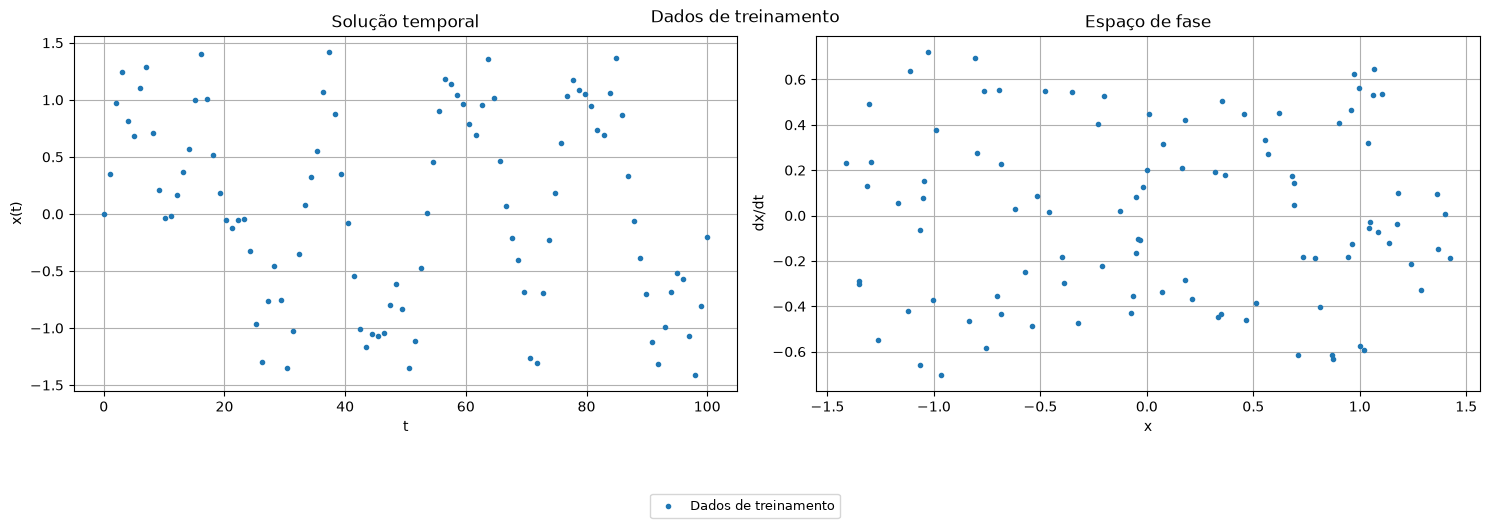

In [ ]:
class Duffing(nn.Module): # a equação de Duffing

    def __init__(self, alpha, beta, delta, gamma, omega):
        super().__init__()

        self.alpha = alpha
        self.beta = beta
        self.delta = delta
        self.gamma = gamma
        self.omega = omega

    def forward(self, t, y):

        x = y[..., 0]
        v = y[..., 1]

        dxdt = v

        dvdt = (
            -self.delta * v
            -self.alpha * x
            -self.beta * x**3
            +self.gamma * torch.cos(self.omega * t)
        )

        return torch.stack([dxdt, dvdt], dim=-1)

class ODEFunc(nn.Module):
    def __init__(self, hidden_dim, num_layers):
        super(ODEFunc, self).__init__()
        layers = []
        in_dim = 3
        for i in range(num_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.Tanh())
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, t, state):
        x = state[..., 0]
        v = state[..., 1]
        t = torch.ones_like(x) * t
        inp = torch.stack([x, v, t], dim=-1)
        dxdt = v
        dvdt = self.net(inp).squeeze(-1)
        return torch.stack([dxdt, dvdt], dim=-1)

class Plot:
    def __init__(self):
        self.fig, self.ax = plt.subplots(1, 2, figsize=(15, 5))

    def plotar(self,t,x,v,label):
        self.ax[0].plot(t, x, '.')
        self.ax[1].plot(x, v, '.', label=label)

    def plotar_traco(self, t, x, v, label):
        self.ax[0].plot(t, x, '--')
        self.ax[1].plot(x, v, '--', label=label)

    def plotar_prev(self, t,x,v):
        self.ax[0].plot(t,x, color='red', lw=0.7)
        self.ax[1].plot(x,v, color='red', lw=0.7, label='Previsão')

    def plotar_fun(self, t,x,v):
        self.ax[0].plot(t,x, color='black', lw=0.7)
        self.ax[1].plot(x,v, color='black', lw=0.7, label='Solução aproximada')

    def plotar_inicial(self, t0, x0, v0):
        self.ax[0].scatter(t0, x0, color='green')
        self.ax[1].scatter(x0, v0, color='green', label='Ponto inicial')

    def exibir(self, titulo, filename=None):
        self.ax[0].set_title(f"Solução temporal")
        self.ax[0].set_xlabel("t")
        self.ax[0].set_ylabel("x(t)")
        self.ax[1].set_title(f"Espaço de fase")
        self.ax[1].set_xlabel("x")
        self.ax[1].set_ylabel("dx/dt")
        self.ax[0].grid(True)
        self.ax[1].grid(True)
        self.fig.legend(
            loc='lower center',
            bbox_to_anchor=(0.5, -0.05),
            ncol=4,
            fontsize=9,
            frameon=True
        )
        plt.tight_layout(rect=[0, 0.10, 1, 1])
        self.fig.suptitle(titulo)
        if filename is not None:
            self.fig.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()

def plotar_erro(t,erro,label):
    plt.plot(t, erro, lw=0.7, label=label)

def exibir_erro(titulo, xlabel, ylabel, log=False, filename=None):
    plt.gcf().set_size_inches(9, 5)
    plt.grid(True)
    if log:
        plt.yscale("log")
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(loc='lower center',
            ncol=6,
            bbox_to_anchor=(0.5, 1.12),
            fontsize=9,
            frameon=True)
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    if filename is not None:
        plt.savefig(fname=filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.clf()

# constantes
gamma = 0.3
alpha = -1.0
beta = 1.0
omega = 1.2
delta = 0.2
# valores iniciais
x0 = 0
v0 = 0.2
# y0 = torch.stack([torch.tensor([x0]), torch.tensor([v0])])
y0 = torch.tensor([x0,v0])

# treinamento
seed = 7880
intervalo = [0,100]
N = 100 # nº de pontos de treinamento
fxy = Duffing(alpha, beta, delta, gamma, omega)
h = (intervalo[1] - intervalo[0])/N
t = torch.linspace(intervalo[0], intervalo[1], N)
sol = odeint(fxy, y0, t)
x = sol[:,0]
v = sol[:,1]
# plotagem
N_plot = 1000 # nº de pontos de plotagem
h_plot = (intervalo[1] - intervalo[0])/N_plot
t_final = torch.linspace(intervalo[0], intervalo[1], N_plot)
t_plot = t_final.detach().squeeze().numpy()
sol_plot = odeint(fxy, y0, t_final).cpu()
x_plot = sol_plot[:,0].detach().squeeze().numpy()
v_plot = sol_plot[:,1].detach().squeeze().numpy()
plot = Plot()
plot.plotar(t, x, v, "Dados de treinamento")
plot.exibir("Dados de treinamento", filename="training_data.png")

# passando pro cuda
y0 = y0.to(device)
x = x.to(device)
v = v.to(device)
t = t.to(device)
t_final = t_final.to(device)

In [ ]:
# busca de hiperparâmetros=
torch.cuda.manual_seed_all(seed)
torch.manual_seed(seed)
np.random.seed(seed)

def objective(trial): # vai treinar 500 épocas e encontrar melhor learning rate, melhor nº de dimensões e melhor nº de camadas
  # hiperparametros
  num_layers = trial.suggest_int("num_layers", 1, 3)
  hidden_dim = trial.suggest_int("dim", 16, 128)
  lr = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
  loss = 10
  rede = ODEFunc(hidden_dim, num_layers).to(device)
  optimizer = optim.Adam(rede.parameters(), lr=lr)
  for epoch in range(500):
    optimizer.zero_grad()
    pred = odeint(rede, y0, t, method="rk4")
    pred_x = pred[:,0]
    pred_v = pred[:,1]
    loss_x = nn.MSELoss()(pred_x, x)
    loss_v = nn.MSELoss()(pred_v, v)
    loss = loss_x + loss_v
    loss.backward()
    optimizer.step()
  return loss.item()

study = optuna.create_study(study_name="hiperparametros",
                            storage="sqlite:///hiperparametros.db",
                            load_if_exists=True,
                            direction='minimize')

study.optimize(objective, n_trials=200)
best_params = study.best_params
print(best_params)
torch.save(best_params, "best_params.pth")

[I 2026-10-27 12:50:15,424] A new study created in RDB with name: hiperparametros
[I 2026-10-27 12:50:50,887] Trial 0 finished with value: 0.8491438627243042 and parameters: {'num_layers': 2, 'dim': 32, 'lr': 0.003223064620106654}. Best is trial 0 with value: 0.8491438627243042.
[I 2026-10-27 12:51:56,727] Trial 1 finished with value: 1.3187944889068604 and parameters: {'num_layers': 2, 'dim': 79, 'lr': 3.881760931683806e-05}. Best is trial 0 with value: 0.8491438627243042.
[I 2026-10-27 12:53:05,529] Trial 2 finished with value: 0.8491162657737732 and parameters: {'num_layers': 2, 'dim': 93, 'lr': 0.0004572745668204007}. Best is trial 2 with value: 0.8491162657737732.
[I 2026-10-27 12:54:14,049] Trial 3 finished with value: 11750.5712890625 and parameters: {'num_layers': 2, 'dim': 78, 'lr': 3.3834716787350796e-05}. Best is trial 2 with value: 0.8491162657737732.
[I 2026-10-27 12:54:50,112] Trial 4 finished with value: 0.904732346534729 and parameters: {'num_layers': 2, 'dim': 33, 'lr'

{'num_layers': 3, 'dim': 73, 'lr': 0.0030638419719690507}


ImportError: Tried to import 'plotly' but failed. Please make sure that the package is installed correctly to use this feature. Actual error: No module named 'plotly'.

In [22]:
# best_params = torch.load("best_params.pth")
best_params = {'num_layers': 3, 'dim': 73, 'lr': 0.0030638419719690507}

torch.use_deterministic_algorithms(True)
torch.manual_seed(seed) 
np.random.seed(seed)
if device == "cuda":
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


n_epochs = 500
previsoes_x = []
previsoes_v = []
erros = []
hidden_dims = best_params["dim"]
num_layers = best_params["num_layers"]
lr = best_params["lr"]
metodos = [
    "euler",
    "midpoint",
    "heun3",
    "rk4",
    "dopri5",
    "dopri8",
]

modelos = dict()
perdas = dict()

import time

def marcar_tempo(device):
  if device == "cuda":
    torch.cuda.synchronize()
  return time.perf_counter()

def experiment(metodo, estado_inicial, best_params):

  func = ODEFunc(hidden_dim=best_params["dim"],
                num_layers=best_params["num_layers"]).to(device)
  optimizer = optim.Adam(func.parameters(),
                        lr=best_params["lr"])
  func.load_state_dict(estado_inicial)
  losses = []
  tempo_total_inicio = marcar_tempo(device)
  tempo_por_epoca = []
  # o loop de treinamento
  for epoch in range(n_epochs):
    inicio_epoca = marcar_tempo(device)

    optimizer.zero_grad()
    pred = odeint(func, y0, t, method=metodo)
    pred_x = pred[:,0]
    pred_v = pred[:,1]

    loss_x = nn.MSELoss()(pred_x, x)
    loss_v = nn.MSELoss()(pred_v, v)
    loss = loss_x + loss_v
    loss.backward()
    optimizer.step()

    fim_epoca = marcar_tempo(device)
    tempo_por_epoca.append(fim_epoca - inicio_epoca)

    losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
      print(f"Epoch {epoch+1}/{n_epochs}, Loss: {loss.item():.6f}")
  tempo_total_fim = marcar_tempo(device)
  tempo_total_treinamento = tempo_total_fim - tempo_total_inicio
  media_epoca = np.mean(np.array(tempo_por_epoca))
  print(f"Treinamento de {metodo} concluído! Tempo total {tempo_total_treinamento:.2f}s, média {media_epoca:.2f}s por época, perda final {losses[-1]:.6f}")
  plotar_erro(np.arange(0, 500, 1), np.array(losses), "MSE")
  exibir_erro("Erro de treinamento", "Época", "MSE", log=True, filename="loss_" + metodo + ".png")

  filename = "NODE_" + metodo + str(seed) + ".pth"
  torch.save(func.state_dict(), filename)
  modelos.update({metodo: filename})
  perdas.update({metodo: losses})

torch.save(modelos, "modelos_dict.pth")
torch.save(perdas, "perdas_dict.pth")


  3%|▎         | 16/500 [00:00<00:15, 31.10it/s]

Epoch 10/500, Loss: 635.092468


  5%|▍         | 24/500 [00:00<00:15, 30.12it/s]

Epoch 20/500, Loss: 364.663330


  7%|▋         | 36/500 [00:01<00:16, 28.83it/s]

Epoch 30/500, Loss: 47.437286


... (90 outputs left out)

 99%|█████████▉| 494/500 [00:18<00:00, 30.46it/s]

Epoch 490/500, Loss: 0.947240


100%|██████████| 500/500 [00:18<00:00, 27.28it/s]


Epoch 500/500, Loss: 0.939908
Treinamento de euler concluído! Tempo total 18.33s, média 0.04s por época, perda final 0.939908


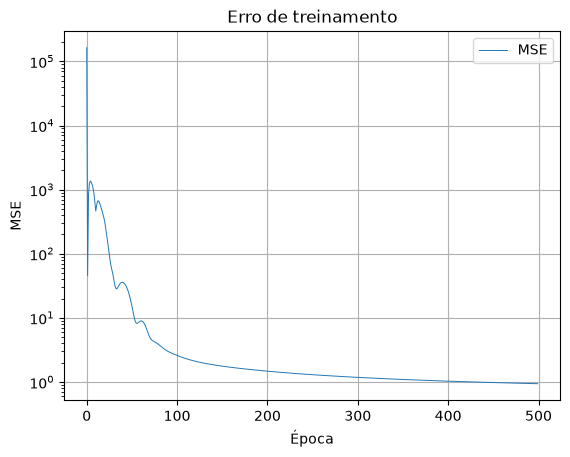

<Figure size 640x480 with 0 Axes>

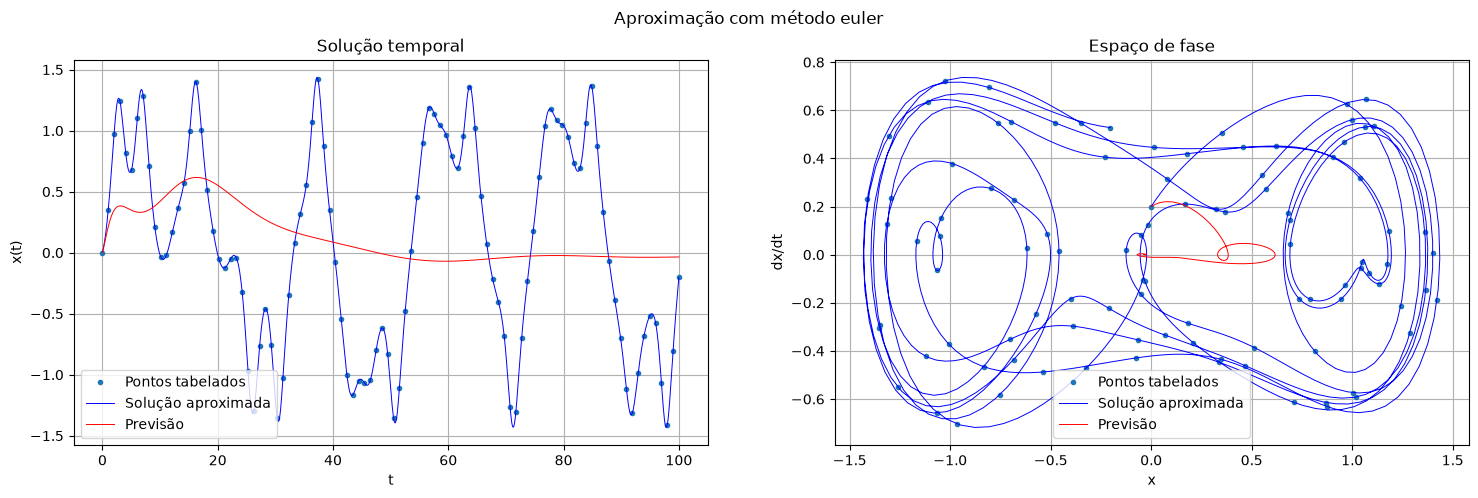

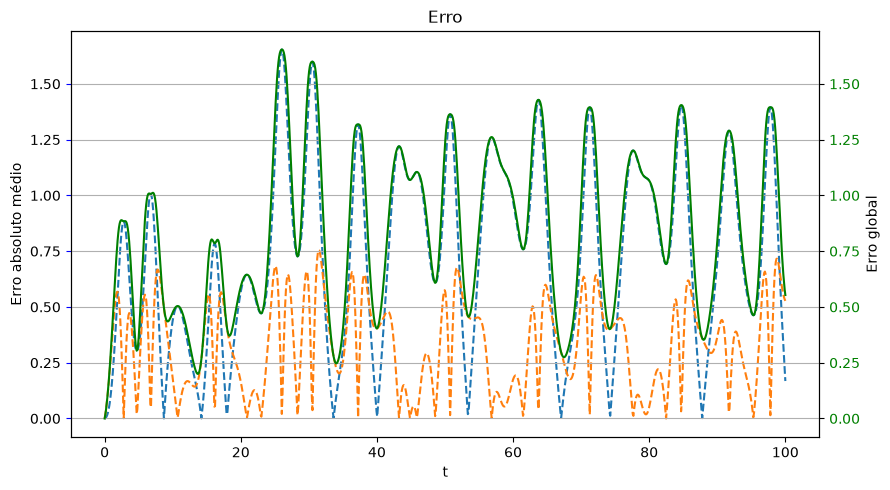

  2%|▏         | 12/500 [00:00<00:28, 17.22it/s]

Epoch 10/500, Loss: 294.322784


  4%|▍         | 22/500 [00:01<00:32, 14.68it/s]

Epoch 20/500, Loss: 121.198486


  6%|▌         | 31/500 [00:01<00:28, 16.24it/s]

Epoch 30/500, Loss: 40.952793


... (90 outputs left out)

 99%|█████████▊| 493/500 [00:33<00:00, 14.69it/s]

Epoch 490/500, Loss: 0.427266


100%|██████████| 500/500 [00:34<00:00, 14.52it/s]


Epoch 500/500, Loss: 0.422722
Treinamento de midpoint concluído! Tempo total 34.42s, média 0.07s por época, perda final 0.422722


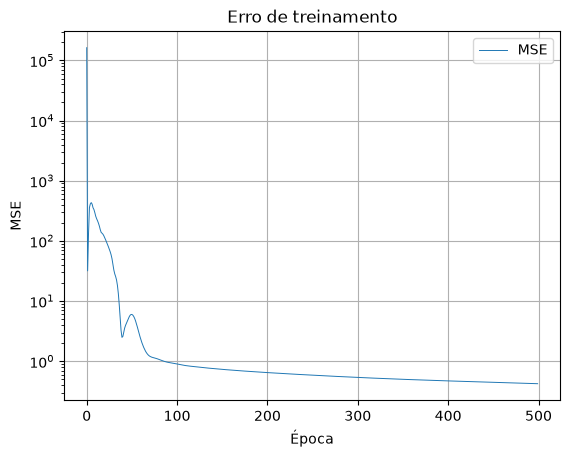

<Figure size 640x480 with 0 Axes>

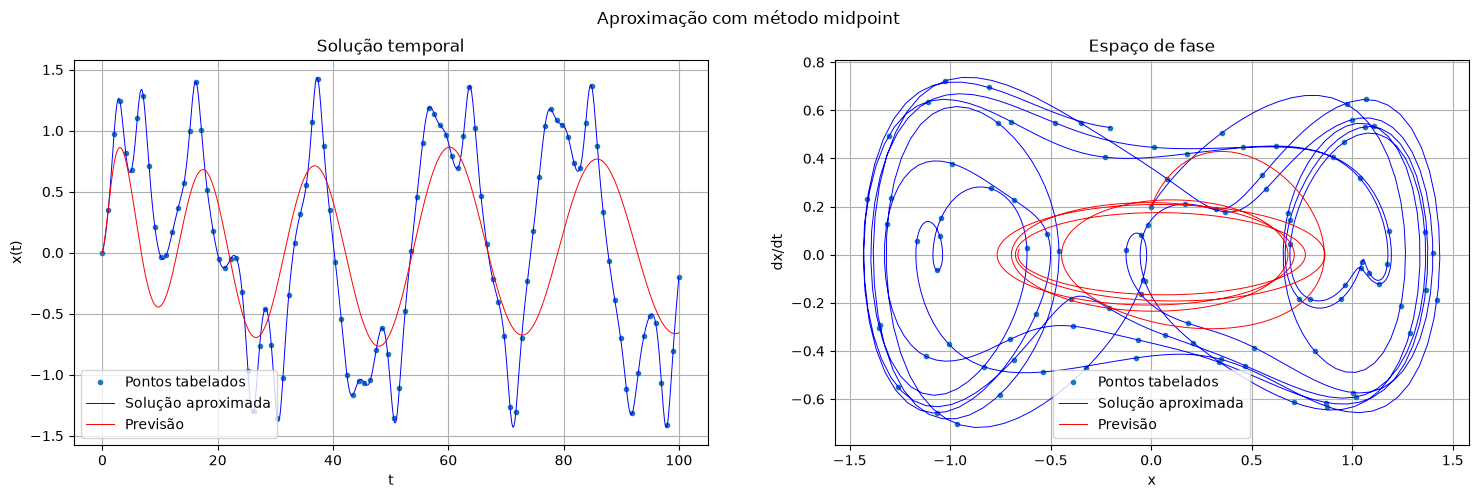

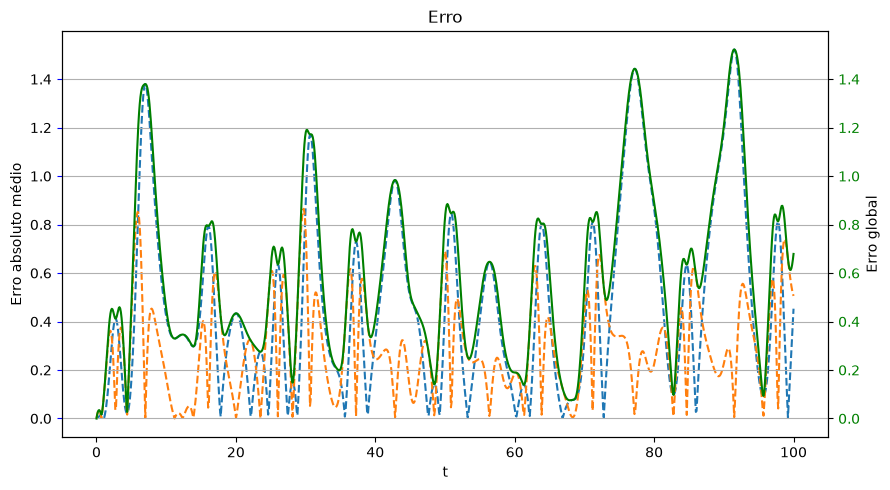

  2%|▏         | 12/500 [00:01<00:51,  9.54it/s]

Epoch 10/500, Loss: 296.703552


  4%|▍         | 21/500 [00:02<00:59,  8.03it/s]

Epoch 20/500, Loss: 116.851654


  6%|▌         | 31/500 [00:03<00:53,  8.79it/s]

Epoch 30/500, Loss: 51.235188


... (90 outputs left out)

 98%|█████████▊| 491/500 [00:59<00:01,  7.50it/s]

Epoch 490/500, Loss: 0.387108


100%|██████████| 500/500 [01:00<00:00,  8.28it/s]


Epoch 500/500, Loss: 0.383757
Treinamento de heun3 concluído! Tempo total 60.35s, média 0.12s por época, perda final 0.383757


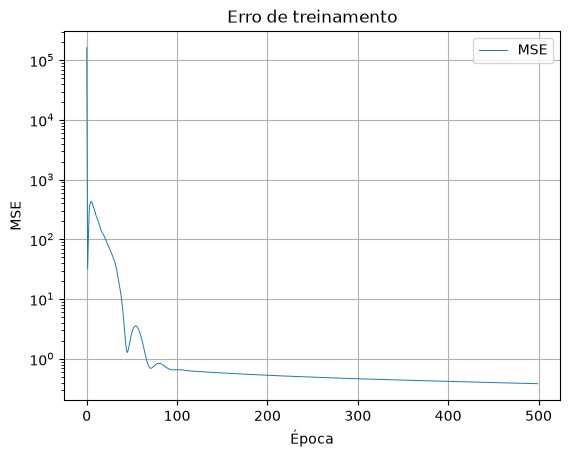

<Figure size 640x480 with 0 Axes>

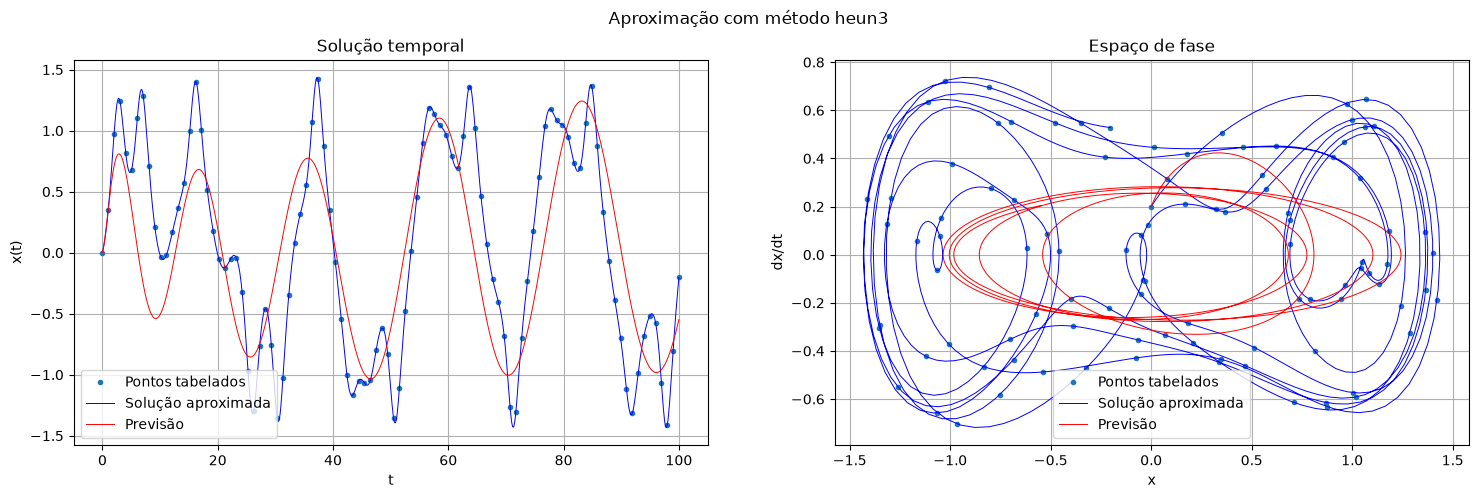

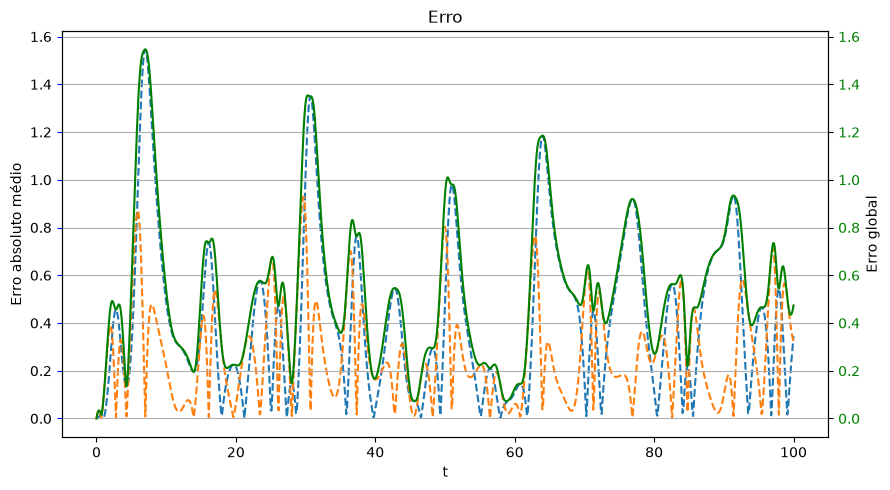

  2%|▏         | 11/500 [00:01<01:20,  6.10it/s]

Epoch 10/500, Loss: 296.783081


  4%|▍         | 21/500 [00:03<01:14,  6.40it/s]

Epoch 20/500, Loss: 117.185379


  6%|▌         | 31/500 [00:04<01:07,  6.99it/s]

Epoch 30/500, Loss: 49.741734


... (90 outputs left out)

 98%|█████████▊| 491/500 [01:15<00:01,  7.13it/s]

Epoch 490/500, Loss: 0.386487


100%|██████████| 500/500 [01:17<00:00,  6.47it/s]


Epoch 500/500, Loss: 0.383150
Treinamento de rk4 concluído! Tempo total 77.23s, média 0.15s por época, perda final 0.383150


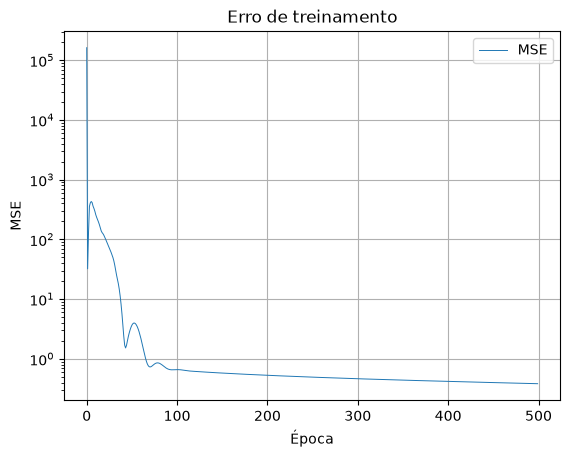

<Figure size 640x480 with 0 Axes>

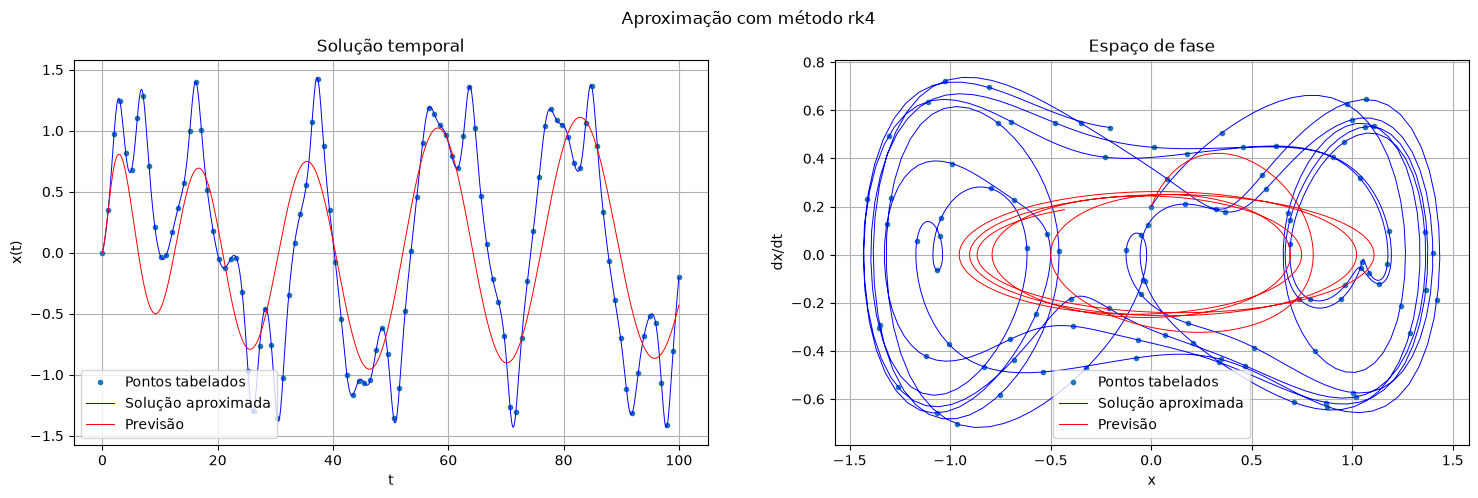

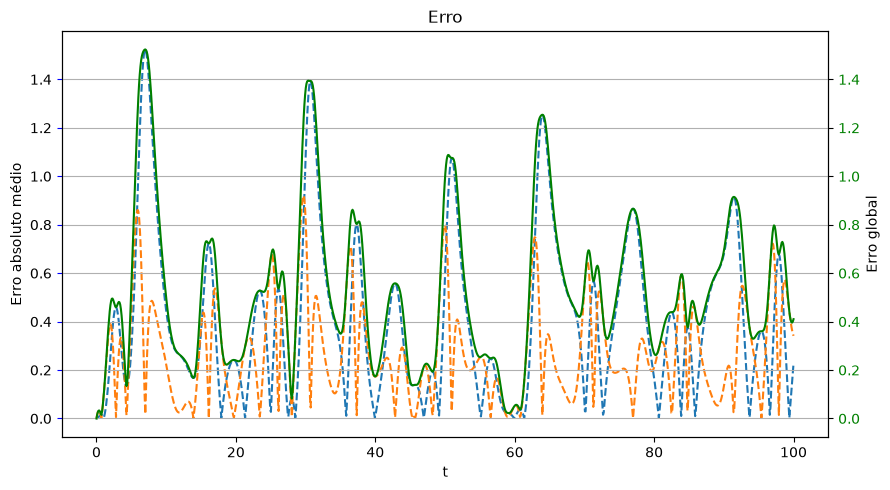

  2%|▏         | 10/500 [00:02<02:27,  3.32it/s]

Epoch 10/500, Loss: 296.780029


  4%|▍         | 20/500 [00:06<03:44,  2.14it/s]

Epoch 20/500, Loss: 117.267860


  6%|▌         | 30/500 [00:12<04:02,  1.94it/s]

Epoch 30/500, Loss: 49.607132


... (90 outputs left out)

 98%|█████████▊| 490/500 [04:37<00:06,  1.64it/s]

Epoch 490/500, Loss: 0.387111


100%|██████████| 500/500 [04:43<00:00,  1.76it/s]

Epoch 500/500, Loss: 0.383741
Treinamento de dopri5 concluído! Tempo total 283.47s, média 0.57s por época, perda final 0.383741


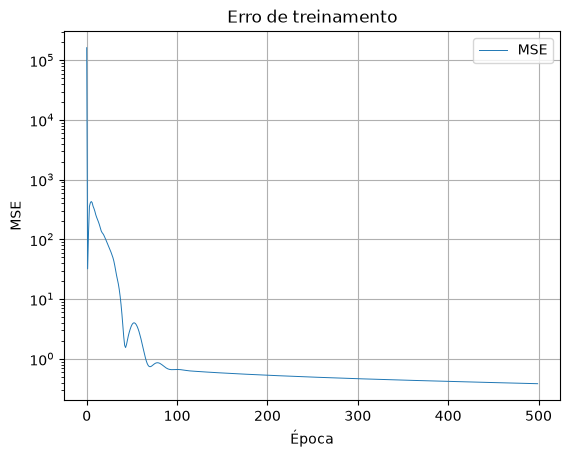

<Figure size 640x480 with 0 Axes>

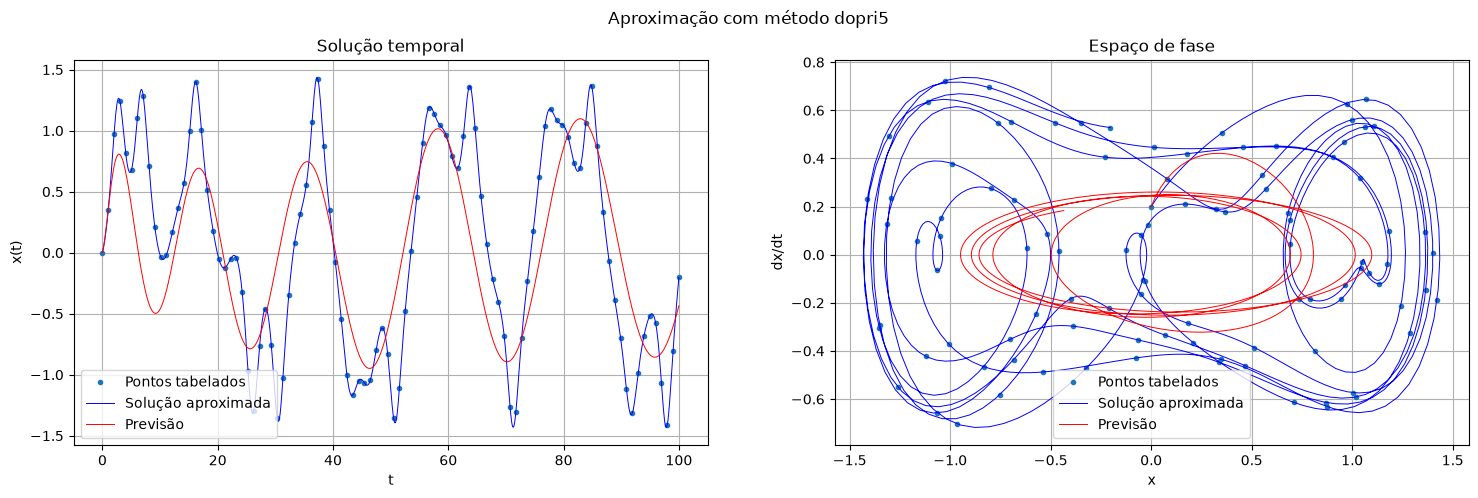

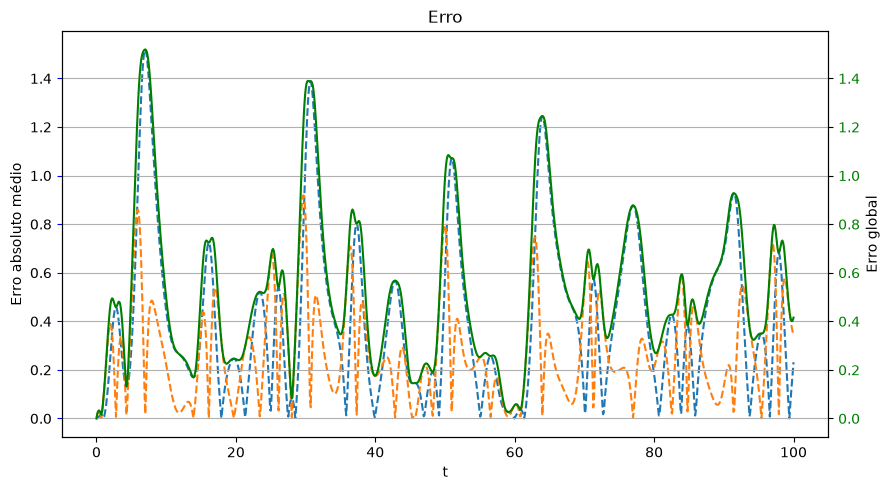

  2%|▏         | 10/500 [00:13<10:54,  1.34s/it]

Epoch 10/500, Loss: 296.771210


  4%|▍         | 20/500 [00:44<27:24,  3.43s/it]

Epoch 20/500, Loss: 117.269913


  6%|▌         | 30/500 [01:09<18:04,  2.31s/it]

Epoch 30/500, Loss: 49.614784


... (90 outputs left out)

 98%|█████████▊| 490/500 [22:06<00:30,  3.00s/it]

Epoch 490/500, Loss: 0.387081


100%|██████████| 500/500 [22:34<00:00,  2.71s/it]

Epoch 500/500, Loss: 0.383712
Treinamento de dopri8 concluído! Tempo total 1354.61s, média 2.71s por época, perda final 0.383712


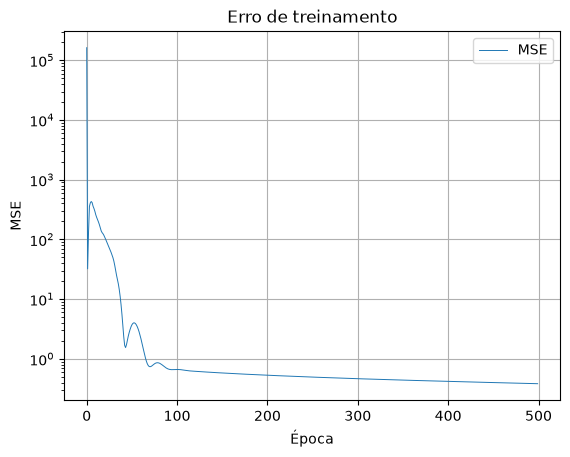

<Figure size 640x480 with 0 Axes>

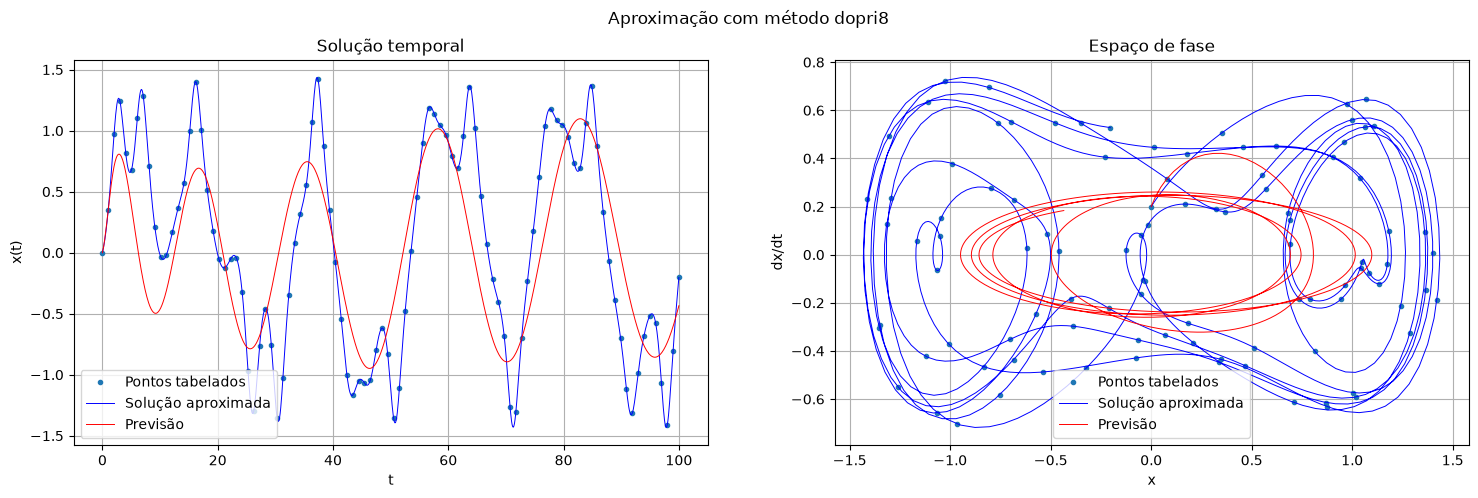

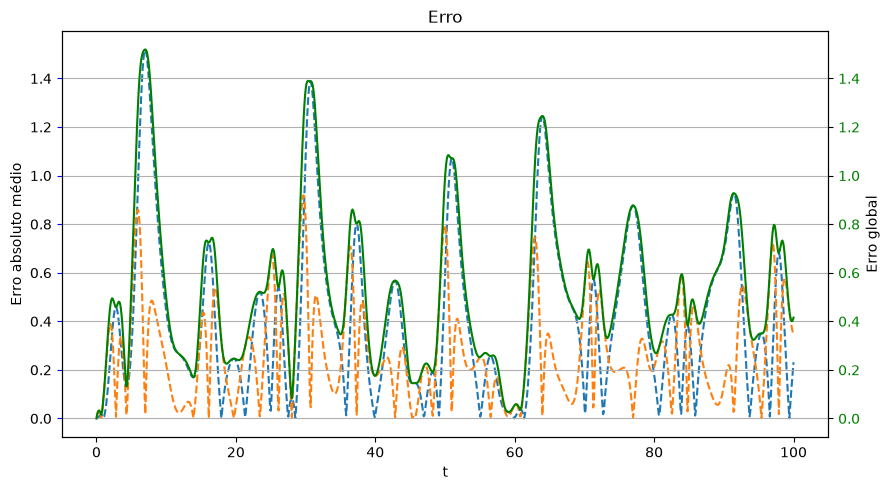

Erros:


ValueError: x and y must have same first dimension, but have shapes (100,) and (1000,)

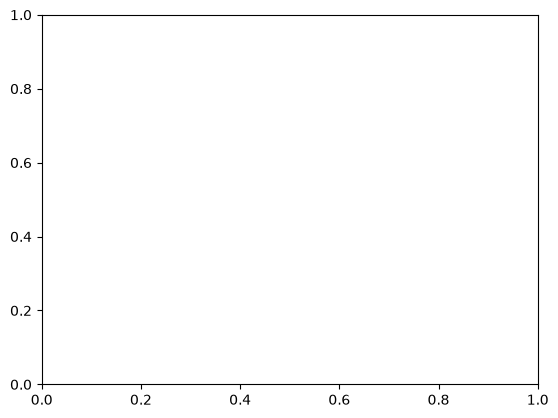

In [ ]:

teste = ODEFunc(hidden_dim=best_params["dim"], num_layers=best_params["num_layers"])
estado_inicial = teste.state_dict()

for i in range(len(metodos)): # treinamento
  experiment(metodos[i], estado_inicial, best_params)

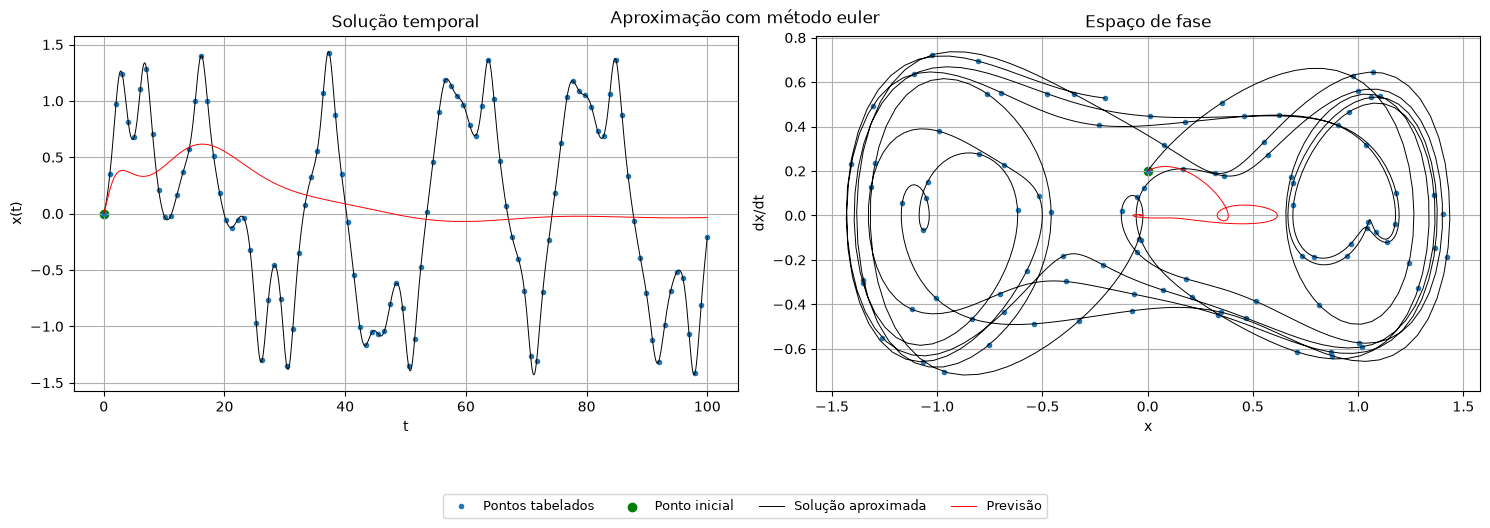

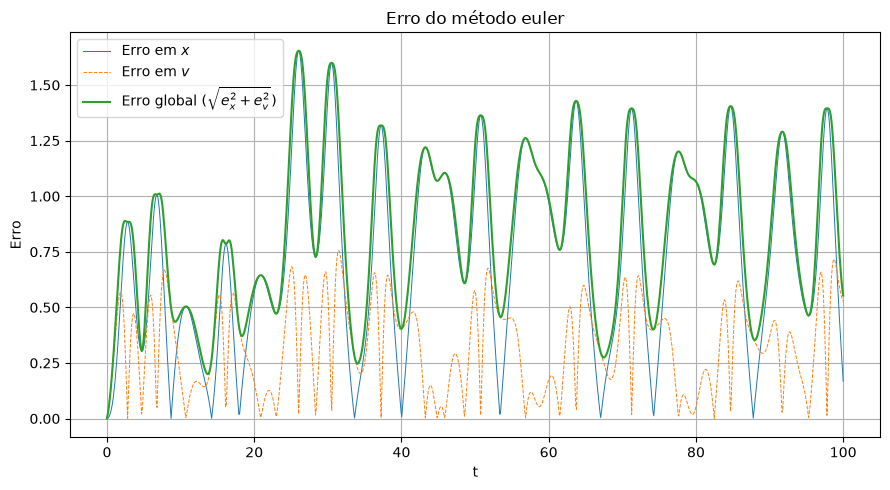

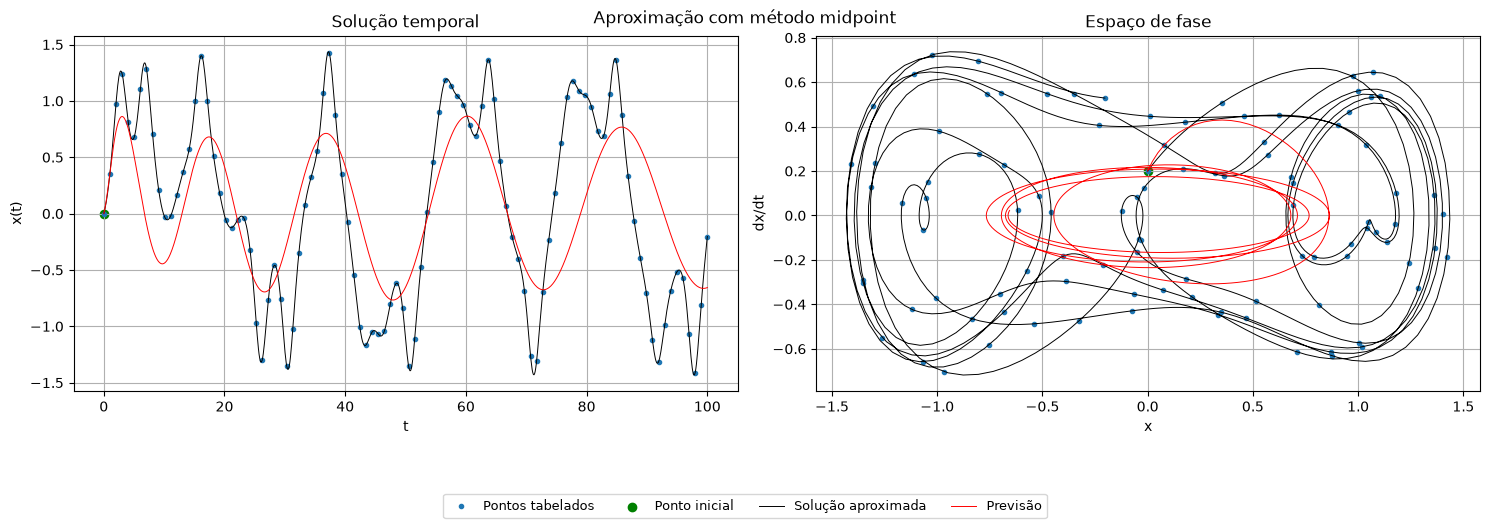

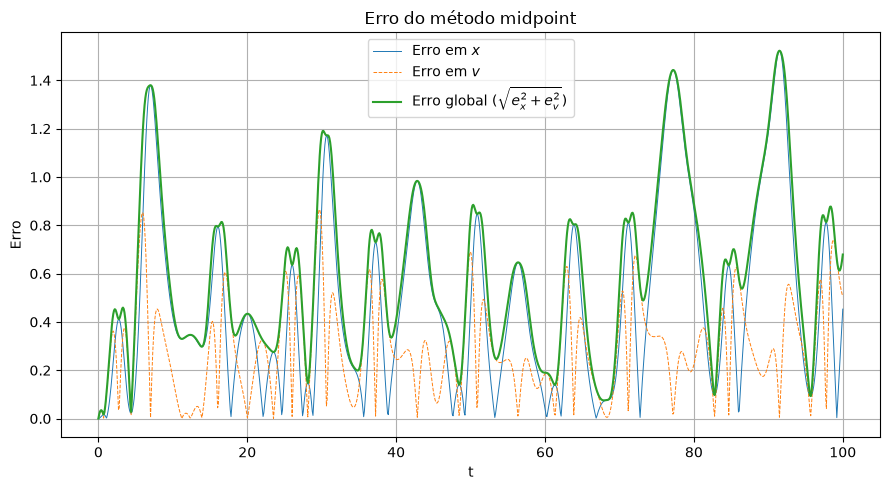

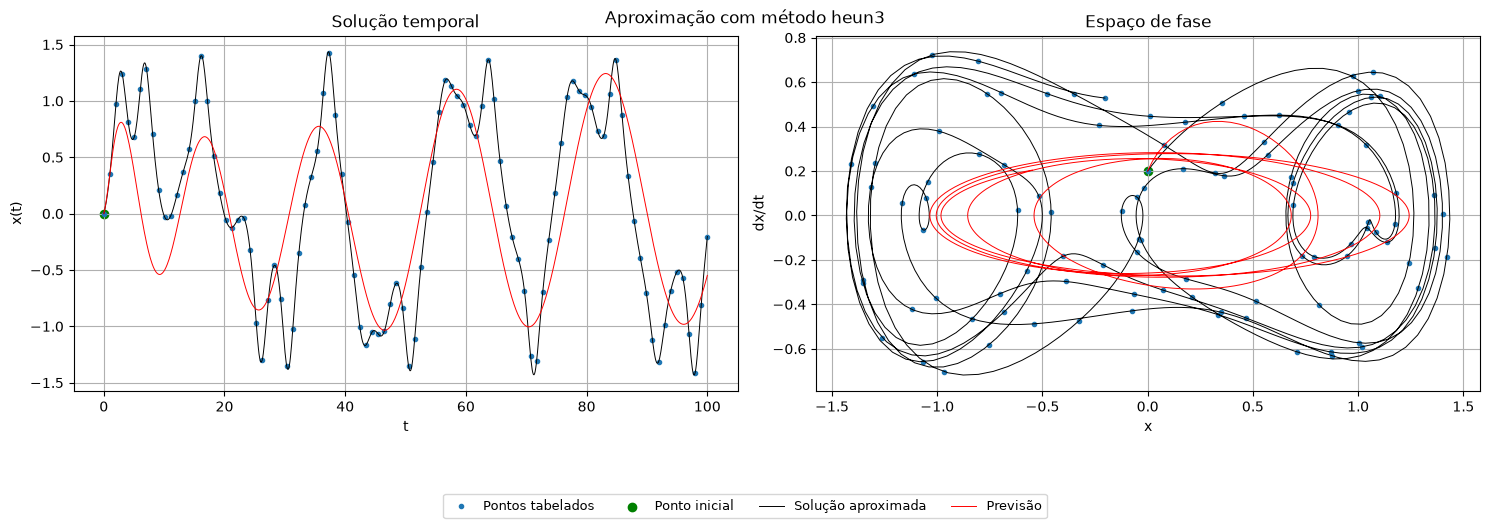

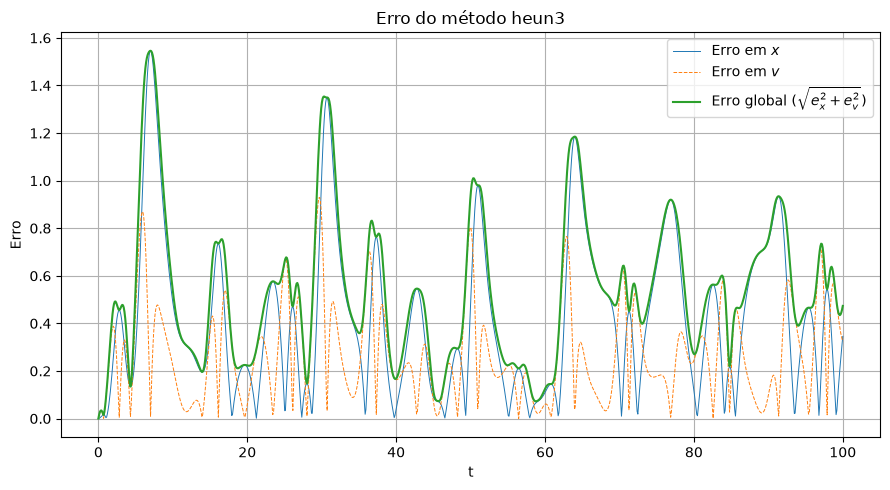

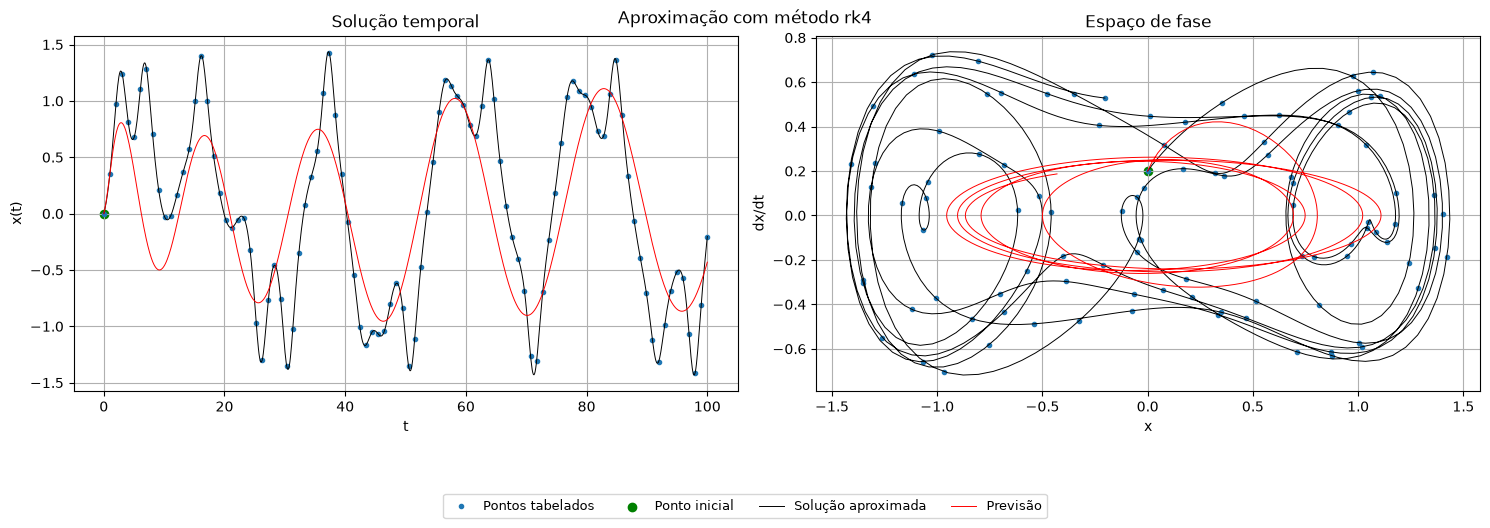

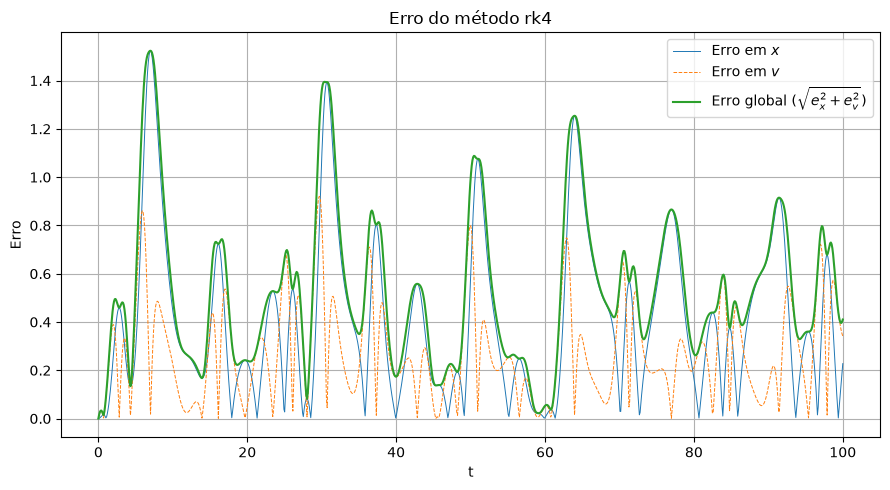

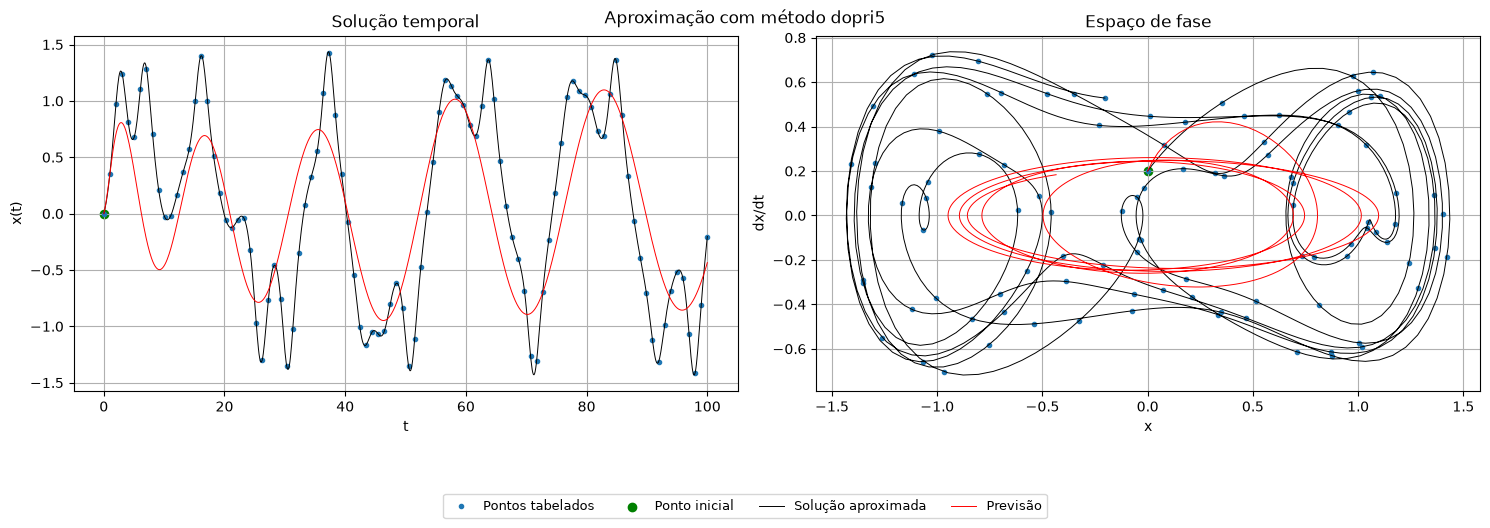

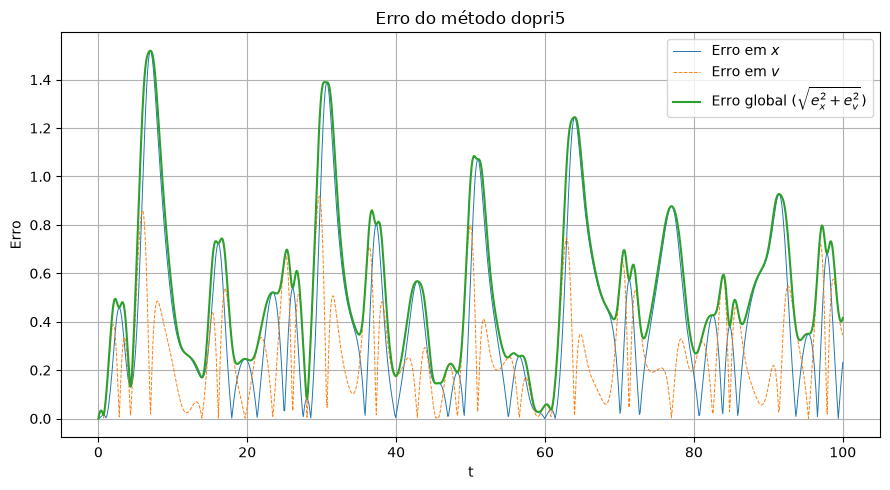

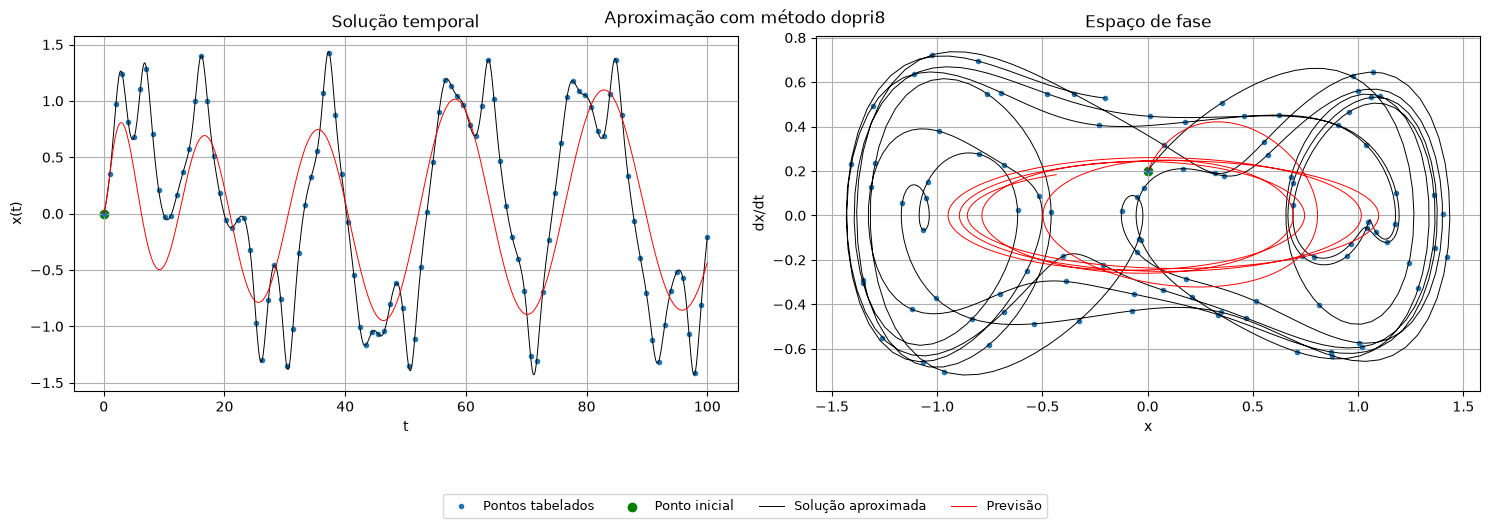

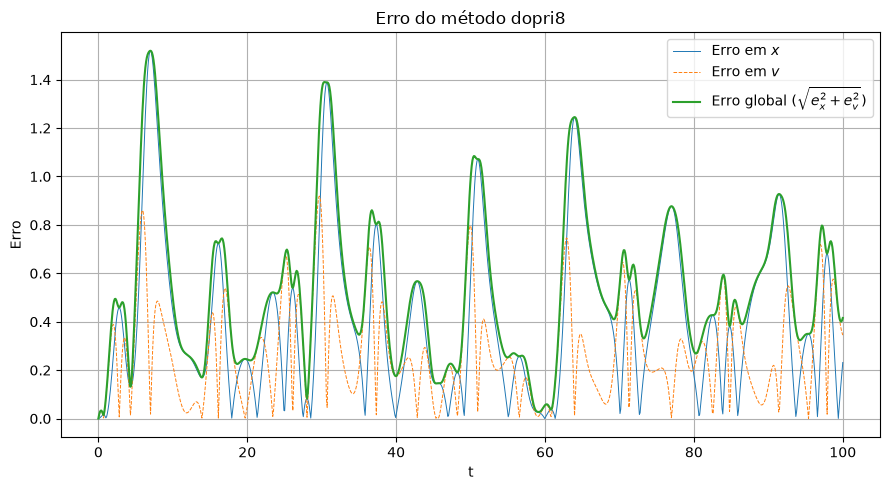

Erros:
euler: 0.8465962409973145
midpoint: 0.6032857894897461
heun3: 0.5438976287841797
rk4: 0.5358087420463562
dopri5: 0.5360279083251953
dopri8: 0.5360129475593567


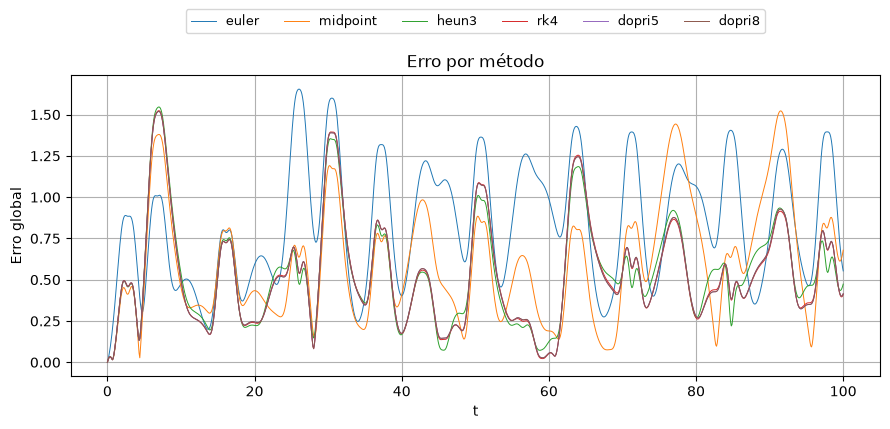

<Figure size 640x480 with 0 Axes>

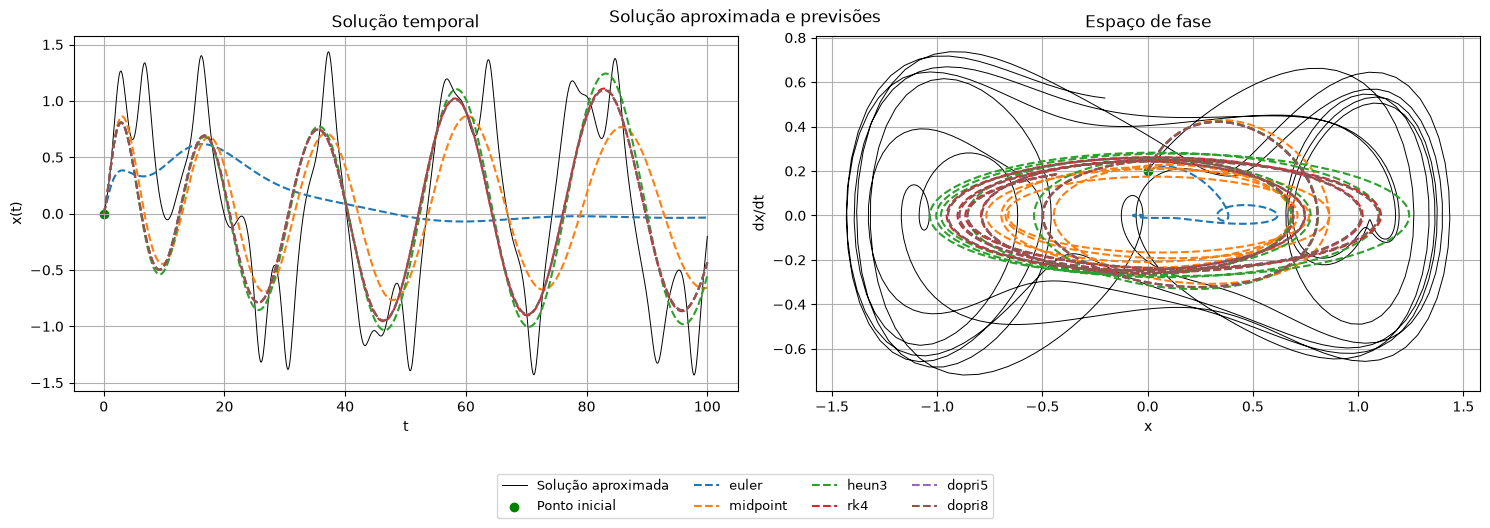

In [71]:
# plotagem
device = "cpu"
perdas = torch.load("perdas_dict.pth")
# modelos = torch.load("modelos_dict.pth")

for metodo in metodos:
  filename = "NODE_" + metodo + str(seed) + ".pth"
  modelos.update({metodo: filename})
#for metodo in metodos:
#  plotar_erro(np.arange(0, 500, 1), np.array(perdas[metodo]), metodo)
#  exibir_erro("Erros de treinamento por método", "Época", "MSE", log=True, filename="loss_geral.png")
erros = []
previsoes_x = []
previsoes_v = []
x_np = x.cpu().detach().squeeze().numpy()
v_np = v.cpu().detach().squeeze().numpy()
t_np = t.cpu().detach().squeeze().numpy()
y0 = y0.to(device)
t_final = t_final.to(device)

for modelo in modelos: # carrega as redes
  
  func = ODEFunc(hidden_dim=best_params["dim"],
                num_layers=best_params["num_layers"]).to(device)
  func.load_state_dict(torch.load(modelos[modelo], weights_only=True))
  # fazer outro predict especificamente pra plotagem
  pred_final = odeint(func, y0, t_final, method=modelo).to(device)
  pred_x_final = pred_final[:,0].detach().squeeze().numpy()
  pred_v_final = pred_final[:,1].detach().squeeze().numpy()
  erro_x = np.abs(pred_x_final - x_plot)
  erro_v = np.abs(pred_v_final - v_plot)
  erro = np.sqrt(erro_x**2 + erro_v**2)
  erros.append(erro)
  previsoes_x.append(pred_x_final)
  previsoes_v.append(pred_v_final)
  plot = Plot()
  plot.plotar(t_np, x_np, v_np, "Pontos tabelados")
  plot.plotar_inicial(0, y0[0], y0[1])
  plot.plotar_fun(t_plot, x_plot, v_plot)
  plot.plotar_prev(t_plot, pred_x_final, pred_v_final)
  plot.exibir(f"Aproximação com método {modelo}", filename=f"grafico_{modelo}.png")

  fig, ax1 = plt.subplots(figsize=(9,5))
  ax1.plot(t_plot, erro_x, label="Erro em $x$", lw=0.7)
  ax1.plot(t_plot, erro_v, '--', label="Erro em $v$", lw=0.7)
  ax1.set_xlabel("t")
  ax1.set_ylabel("Erro")
  ax1.plot(t_plot, erro, label="Erro global ($\\sqrt{e_x^2 + e_v^2}$)")
  plt.title(f"Erro do método {modelo}")
  fig.tight_layout()
  ax1.legend()
  plt.grid()
  plt.savefig(f"erro_NODE_{modelo}_{seed}.png")
  plt.show()

erro_medio = []
print("Erros:")
for i in range(len(metodos)):
  plotar_erro(t_plot, erros[i], metodos[i])
  erro_medio.append(np.mean(erros[i]))
  print(f"{metodos[i]}: {erro_medio[i]}")
exibir_erro("Erro por método", xlabel="t", ylabel="Erro global", filename="erro_geral.png")

plot = Plot()
plot.plotar_fun(t_plot, x_plot, v_plot)
plot.plotar_inicial(0, y0[0], y0[1])
for i in range(len(metodos)):
  plot.plotar_traco(t_plot,
                    previsoes_x[i],
                    previsoes_v[i],
                    metodos[i])
plot.exibir("Solução aproximada e previsões", filename="grafico_geral.png")
